In [ ]:
import tensorflow as tf
tf.config.list_physical_devices('GPU')


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [ ]:
!wget -O NuInsSeg.zip https://zenodo.org/records/10518968/files/NuInsSeg.zip


--2026-02-13 10:06:15--  https://zenodo.org/records/10518968/files/NuInsSeg.zip
Resolving zenodo.org (zenodo.org)... 137.138.52.235, 188.185.48.75, 188.185.43.153, ...
Connecting to zenodo.org (zenodo.org)|137.138.52.235|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1627427342 (1.5G) [application/octet-stream]
Saving to: ‘NuInsSeg.zip’

NuInsSeg.zip        100%[===================>]   1.52G  12.9MB/s    in 2m 4s   

2026-02-13 10:08:20 (12.5 MB/s) - ‘NuInsSeg.zip’ saved [1627427342/1627427342]



In [ ]:
import zipfile
import os

with zipfile.ZipFile("NuInsSeg.zip", "r") as zip_ref:
    zip_ref.extractall("/content/NuInsSeg")

print("Dataset extracted to /content/NuInsSeg")


Dataset extracted to /content/NuInsSeg


In [ ]:
from pathlib import Path

DATA_ROOT = "/content/NuInsSeg"
pairs = []

for organ in os.listdir(DATA_ROOT):
    organ_path = os.path.join(DATA_ROOT, organ)
    if not os.path.isdir(organ_path):
        continue

    img_dir, mask_dir = None, None

    for path, dirs, files in os.walk(organ_path):
        lname = path.lower()
        if "image" in lname:
            img_dir = path
        if "mask" in lname:
            mask_dir = path

    if not img_dir or not mask_dir:
        continue

    imgs  = sorted(os.listdir(img_dir))
    masks = sorted(os.listdir(mask_dir))

    mask_map = {Path(m).stem: m for m in masks}

    for img in imgs:
        key = Path(img).stem
        if key in mask_map:
            pairs.append((
                os.path.join(img_dir, img),
                os.path.join(mask_dir, mask_map[key])
            ))

print("✅ Total valid image–mask pairs:", len(pairs))


✅ Total valid image–mask pairs: 665


In [ ]:
!pip install opencv-python


In [ ]:
import cv2, math
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate
from tensorflow.keras.utils import Sequence


In [ ]:
IMG_SIZE = 256

def preprocess_image(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return img / 255.0

def preprocess_mask(path):
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
    mask = (mask / 255.0).astype("float32")
    return np.expand_dims(mask, -1)



In [ ]:
class NuInsSegAllOrgansGen(Sequence):
    def __init__(self, pairs, batch_size=8):
        self.pairs = pairs
        self.batch_size = batch_size

    def __len__(self):
        return math.ceil(len(self.pairs) / self.batch_size)

    def __getitem__(self, idx):
        batch_pairs = self.pairs[
            idx*self.batch_size:(idx+1)*self.batch_size
        ]

        X, y = [], []
        for img_path, mask_path in batch_pairs:
            X.append(preprocess_image(img_path))
            y.append(preprocess_mask(mask_path))

        return np.array(X), np.array(y)


In [ ]:
train_gen = NuInsSegAllOrgansGen(
    pairs,
    batch_size=8
)

print("Steps per epoch:", len(train_gen))


Steps per epoch: 84


(8, 256, 256, 3) (8, 256, 256, 1)


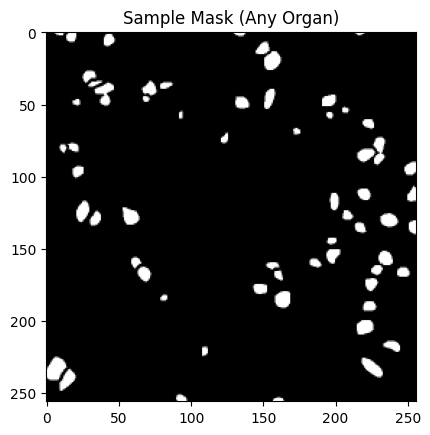

In [ ]:
x, y = train_gen[0]
print(x.shape, y.shape)

plt.imshow(y[0].squeeze(), cmap="gray")
plt.title("Sample Mask (Any Organ)")
plt.show()


In [ ]:
def dice_coef(y_true, y_pred, smooth=1):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )


def iou_metric(y_true, y_pred, smooth=1):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > 0.5, tf.float32)  # 🔥 threshold

    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection

    return (intersection + smooth) / (union + smooth)



In [ ]:
inputs = Input((256,256,3))

c1 = Conv2D(16,3,activation='relu',padding='same')(inputs)
p1 = MaxPooling2D()(c1)

c2 = Conv2D(32,3,activation='relu',padding='same')(p1)
p2 = MaxPooling2D()(c2)

c3 = Conv2D(64,3,activation='relu',padding='same')(p2)

u1 = UpSampling2D()(c3)
m1 = concatenate([u1,c2])
c4 = Conv2D(32,3,activation='relu',padding='same')(m1)

u2 = UpSampling2D()(c4)
m2 = concatenate([u2,c1])
c5 = Conv2D(16,3,activation='relu',padding='same')(m2)

outputs = Conv2D(1,1,activation='sigmoid')(c5)

model = Model(inputs, outputs)


In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", dice_coef, iou_metric]
)


In [ ]:
history = model.fit(
    train_gen,
    epochs=50
)


Epoch 1/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 117ms/step - accuracy: 0.9010 - dice_coef: 0.4778 - iou_metric: 0.4287 - loss: 0.2153
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.8991 - dice_coef: 0.5139 - iou_metric: 0.4647 - loss: 0.2164
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 93ms/step - accuracy: 0.8919 - dice_coef: 0.4909 - iou_metric: 0.4545 - loss: 0.2293
Epoch 4/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 101ms/step - accuracy: 0.8903 - dice_coef: 0.4927 - iou_metric: 0.4366 - loss: 0.2312
Epoch 5/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 105ms/step - accuracy: 0.8931 - dice_coef: 0.4871 - iou_metric: 0.4454 - loss: 0.2243
Epoch 6/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 99ms/step - accuracy: 0.8941 - dice_coef: 0.4698 - iou_metric: 0.4247 - loss: 0.2315
Epoch 7/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.8948 - dice_coef: 0.5138 - iou_metric: 0.4687 - loss: 0.2246
Epoch 8/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.9010 - dice_coef: 0.5074 - iou_metric: 0.4602 

In [ ]:
history2 = model.fit(
    train_gen,
    initial_epoch=20,
    epochs=50
)


Epoch 21/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.9107 - dice_coef: 0.5128 - iou_metric: 0.4597 - loss: 0.1895
Epoch 22/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - accuracy: 0.9084 - dice_coef: 0.5516 - iou_metric: 0.5026 - loss: 0.1882
Epoch 23/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/step - accuracy: 0.9063 - dice_coef: 0.5449 - iou_metric: 0.4906 - loss: 0.1927
Epoch 24/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 101ms/step - accuracy: 0.9093 - dice_coef: 0.5732 - iou_metric: 0.5307 - loss: 0.1844
Epoch 25/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.9037 - dice_coef: 0.5678 - iou_metric: 0.5187 - loss: 0.1955
Epoch 26/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 97ms/step - accuracy: 0.9213 - dice_coef: 0.5673 - iou_metric: 0.5170 - loss: 0.1608
Epoch 27/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 106ms/step - accuracy: 0.9168 - dice_coef: 0.5424 - iou_metric: 0.5014 - loss: 0.1729
Epoch 28/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.9169 - dice_coef: 0.5488 - iou_metric: 

In [ ]:
history3 = model.fit(
    train_gen,
    initial_epoch=50,
    epochs=100
)


Epoch 51/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.9236 - dice_coef: 0.5801 - iou_metric: 0.5343 - loss: 0.1567
Epoch 52/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.9206 - dice_coef: 0.5645 - iou_metric: 0.5199 - loss: 0.1665
Epoch 53/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - accuracy: 0.9137 - dice_coef: 0.5882 - iou_metric: 0.5374 - loss: 0.1759
Epoch 54/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.9303 - dice_coef: 0.5673 - iou_metric: 0.5154 - loss: 0.1453
Epoch 55/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.9135 - dice_coef: 0.5849 - iou_metric: 0.5358 - loss: 0.1788
Epoch 56/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step - accuracy: 0.9165 - dice_coef: 0.5769 - iou_metric: 0.5290 - loss: 0.1701
Epoch 57/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.9171 - dice_coef: 0.5826 - iou_metric: 0.5295 - loss: 0.1722
Epoch 58/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 103ms/step - accuracy: 0.9214 - dice_coef: 0.5546 - iou_

In [ ]:
history3 = model.fit(
    train_gen,
    initial_epoch=100,
    epochs=200
)


Epoch 101/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.9248 - dice_coef: 0.6075 - iou_metric: 0.5430 - loss: 0.1518
Epoch 102/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.9276 - dice_coef: 0.5968 - iou_metric: 0.5522 - loss: 0.1456
Epoch 103/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.9174 - dice_coef: 0.6193 - iou_metric: 0.5657 - loss: 0.1648
Epoch 104/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.9233 - dice_coef: 0.6074 - iou_metric: 0.5601 - loss: 0.1529
Epoch 105/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.9284 - dice_coef: 0.6143 - iou_metric: 0.5591 - loss: 0.1440
Epoch 106/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 97ms/step - accuracy: 0.9249 - dice_coef: 0.6018 - iou_metric: 0.5500 - loss: 0.1500
Epoch 107/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.9214 - dice_coef: 0.6171 - iou_metric: 0.5623 - loss: 0.1597
Epoch 108/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 103ms/step - accuracy: 0.9198 - dice_coef: 0.627

In [ ]:
import numpy as np

def dice_np(y_true, y_pred, smooth=1):
    y_true = y_true.astype("float32").flatten()
    y_pred = y_pred.astype("float32").flatten()
    intersection = np.sum(y_true * y_pred)
    return (2. * intersection + smooth) / (
        np.sum(y_true) + np.sum(y_pred) + smooth
    )

def iou_np(y_true, y_pred, smooth=1):
    y_true = y_true.astype("float32").flatten()
    y_pred = y_pred.astype("float32").flatten()
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


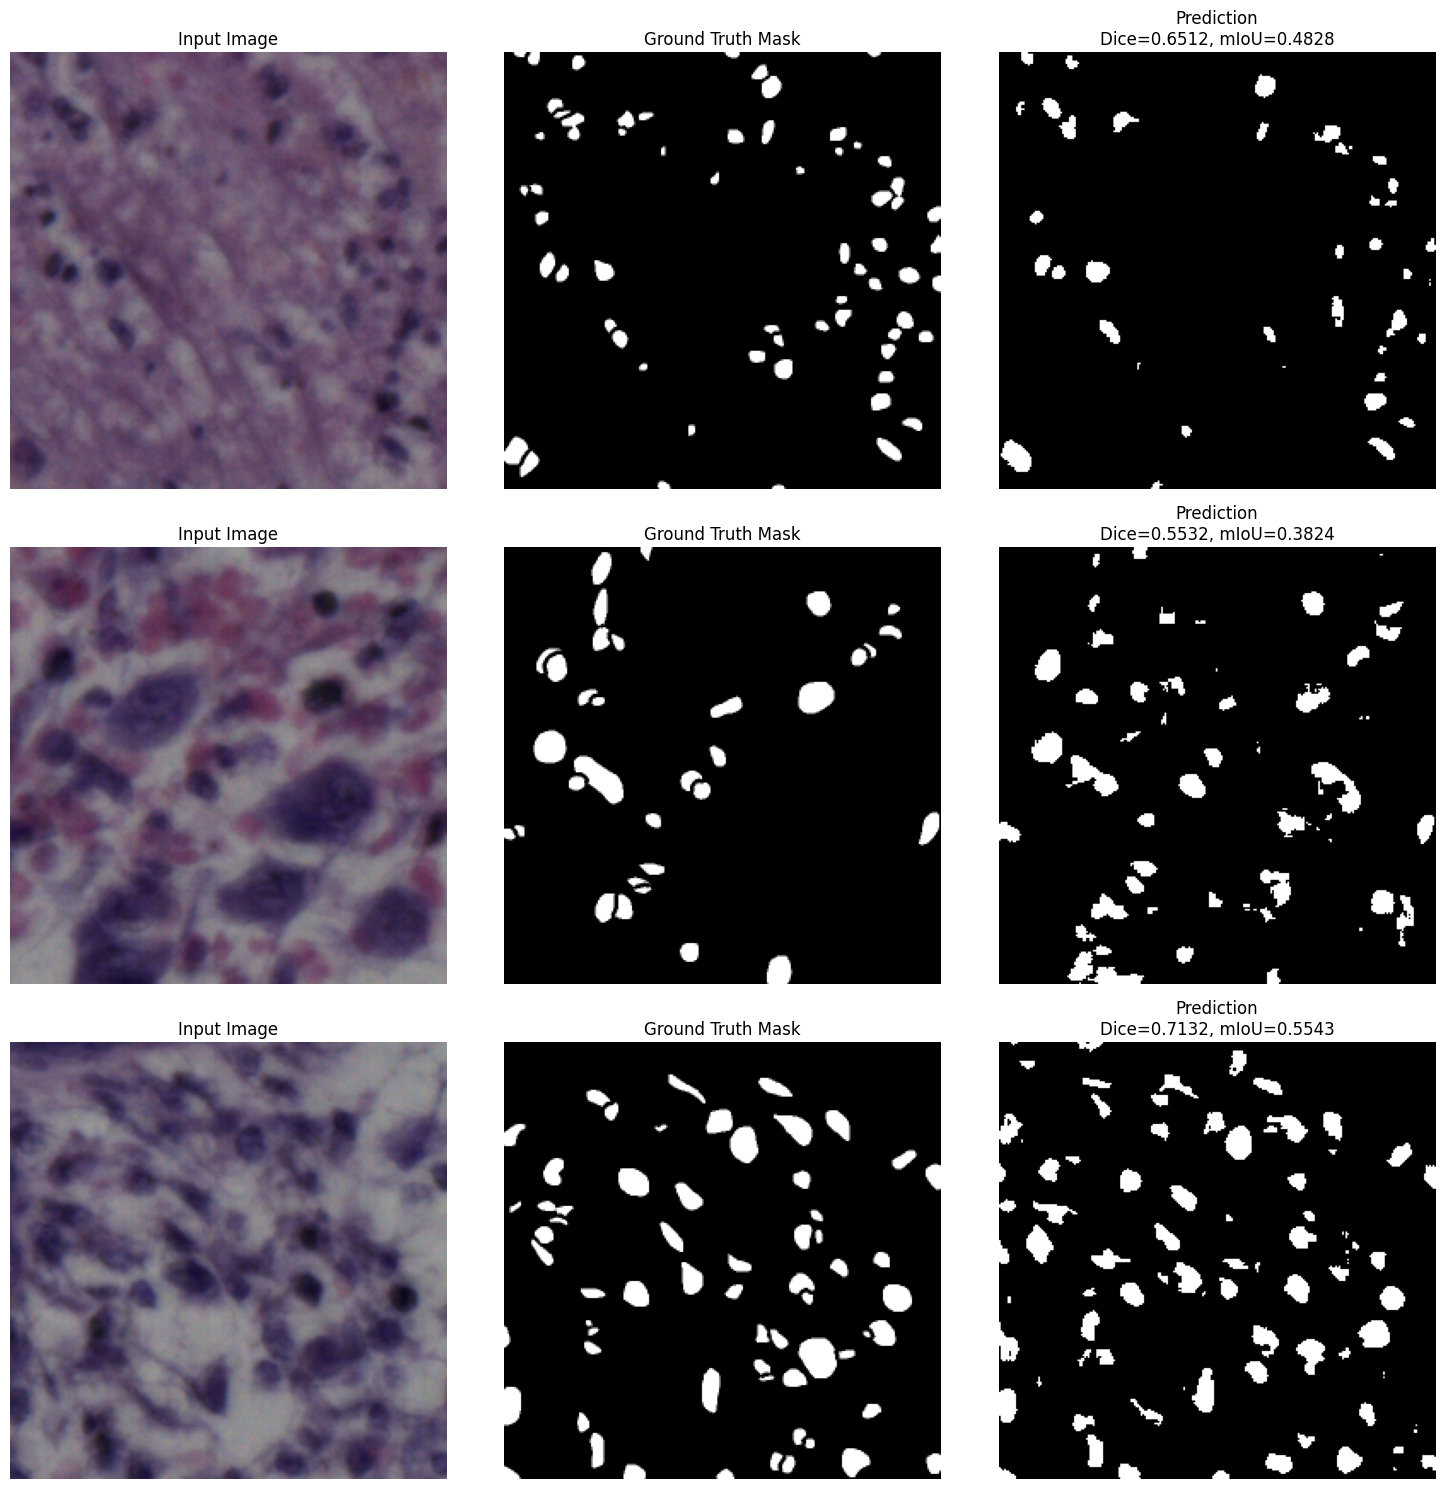

In [ ]:
# Get one batch safely
x, y = train_gen[0]

# Predict masks
pred = model.predict(x)

# Convert probabilities → binary masks
pred_bin = (pred > 0.5).astype("float32")

import matplotlib.pyplot as plt

num_samples = min(3, x.shape[0])
plt.figure(figsize=(15, 5 * num_samples))

for i in range(num_samples):
    # Compute metrics per image
    dice_score = dice_np(y[i], pred_bin[i])
    iou_score  = iou_np(y[i], pred_bin[i])

    # Input image
    plt.subplot(num_samples, 3, 3*i + 1)
    plt.imshow(x[i])
    plt.title("Input Image")
    plt.axis("off")

    # Ground truth mask
    plt.subplot(num_samples, 3, 3*i + 2)
    plt.imshow(y[i].squeeze(), cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    # Predicted mask + metrics
    plt.subplot(num_samples, 3, 3*i + 3)
    plt.imshow(pred_bin[i].squeeze(), cmap="gray")
    plt.title(f"Prediction\nDice={dice_score:.4f}, mIoU={iou_score:.4f}")
    plt.axis("off")

plt.tight_layout()
plt.show()
